# Lab 2 — Partie 2 : Vision Transformer (ViT) sur MNIST (PyTorch)
#
# **Dataset** : le même MNIST que la partie 1. **Idée du ViT** (Dosovitskiy et al., 2020) : couper l'image en
# **patchs**, transformer chaque patch en vecteur, ajouter une **position apprise**, puis laisser des couches
# d'**attention multi-têtes** traiter la séquence ; un jeton de classe (CLS) résume la séquence pour la prédiction.
#
# **Choix effectués :**
#
# - patch 4×4 -> une image 28×28 donne **49 patchs** (7×7), comme dans le tutoriel de référence de l'énoncé ;
# - embedding 64, **4 têtes d'attention**, 4 blocs Transformer, MLP interne 128, Dropout 0.1 ;
# - jeton **CLS** appris + embeddings de position appris (position sinusoidale non nécessaire sur 49 patchs) ;
# - optimiseur Adam, lr 0.001, weight decay 1e-4, **10 epochs**.
#
# ---

In [ ]:
# Cellule de mise en place : imports + verification du materiel (mode GPU exigé par l'enonce)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import time

SEED = 42
torch.manual_seed(SEED)

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"GPU disponible : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Carte : {torch.cuda.get_device_name(0)}")
    device = torch.device("cuda")
else:
    print("Runtime en CPU -> changer : Execution > Modifier le type d'execution > T4 GPU")
    device = torch.device("cpu")

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU disponible : True
Carte : Tesla T4


In [ ]:
# Dataset MNIST — identique a la partie 1 (60 000 train / 10 000 test)
# On garde les mêmes transformers et les mêmes batchs : la comparaison avec le CNN (partie 1)
# est faite sur exactement les mêmes données.
train_set = torchvision.datasets.MNIST(root="/content/data", train=True,  download=True, transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
]))
test_set = torchvision.datasets.MNIST(root="/content/data", train=False, download=True, transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
]))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=2)

print(f"Train : {len(train_set)} images | Test : {len(test_set)} images")

Train : 60000 images | Test : 10000 images


In [ ]:
# Architecture ViT construite de zero avec PyTorch (question 1 de la partie 2)
#
# 1. PatchEmbedding : l'image 28x28 est decoupee en patchs 4x4 (pas de recouvrement), chaque patch
#    aplatit 4x4x1 = 16 valeurs et devient via une Conv2d un vecteur de dimension 64 (une projection apprise).
# 2. Jeton CLS : un vecteur appris est ajoute en tete de la sequence (point de résumé global de l'image).
# 3. PositionEmbedding : 49+1 = 50 embeddings appris, ajoutés aux jetons.
# 4. Attention multi-têtes : chaque token regarde tous les autres ; 4 têtes de dimension 64/4 = 16.
# 5. Bloc Transformer : Attention -> MLP, normalisation avant (Pre-Norm) et connnexions residuelles.
# 6. Tête de classification : le jeton CLS final passe dans une couche Lineare -> 10 logits.

class MultiHeadAttention(nn.Module):
    def __init__(self, dim, tetes, dropout=0.1):
        super().__init__()
        self.dim, self.tetes = dim, tetes
        self.dim_tete = dim // tetes
        self.qkv    = nn.Linear(dim, 3 * dim)
        self.projet = nn.Linear(dim, dim)
        self.drop   = nn.Dropout(dropout)

    def forward(self, x):
        batch, seq, _ = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        # redimensionnement : (batch, seq, dim) -> (batch, tete, seq, dim_tete)
        vue = lambda t: t.view(batch, seq, self.tetes, self.dim_tete).transpose(1, 2)
        q, k, v = vue(q), vue(k), vue(v)
        att = torch.matmul(q, k.transpose(-2, -1)) / (self.dim_tete ** 0.5)   # scores d'attention
        att = self.drop(att.softmax(dim=-1))
        out = torch.matmul(att, v)
        out = out.transpose(1, 2).reshape(batch, seq, self.dim)
        return self.drop(self.projet(out))

class BlocTransformer(nn.Module):
    # Pre-Norm : normaliser avant le sous-bloc (plus stable que le Post-Norm du tutoriel)
    def __init__(self, dim, tetes, mlp_dim, dropout=0.1):
        super().__init__()
        self.norm1     = nn.LayerNorm(dim)
        self.attention = MultiHeadAttention(dim, tetes, dropout)
        self.norm2     = nn.LayerNorm(dim)
        self.mlp       = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))     # connexion residuelle
        x = x + self.mlp(self.norm2(x))
        return x

class ViT(nn.Module):
    def __init__(self, taille_image=28, taille_patch=4, dim=64, profondeur=4, tetes=4, mlp_dim=128, n_classes=10, dropout=0.1):
        super().__init__()
        n_patch = (taille_image // taille_patch) ** 2                   # 49
        self.patch = nn.Conv2d(1, dim, kernel_size=taille_patch, stride=taille_patch)  # decoupe + projection
        self.cls   = nn.Parameter(torch.zeros(1, 1, dim))               # jeton de classe appris
        self.pos   = nn.Parameter(torch.zeros(1, n_patch + 1, dim))     # embeddings de position appris
        self.drop  = nn.Dropout(dropout)
        self.blocs = nn.ModuleList([BlocTransformer(dim, tetes, mlp_dim, dropout) for _ in range(profondeur)])
        self.norm  = nn.LayerNorm(dim)
        self.tete  = nn.Linear(dim, n_classes)

    def forward(self, x):
        patchs = self.patch(x).flatten(2).transpose(1, 2)               # (batch, 49, 64)
        jetons = torch.cat([self.cls.expand(patchs.shape[0], -1, -1), patchs], dim=1)   # (batch, 50, 64)
        jetons = self.drop(jetons + self.pos)
        for bloc in self.blocs:
            jetons = bloc(jetons)
        cls_final = self.norm(jetons[:, 0])                             # on ne lit que le jeton CLS
        return self.tete(cls_final)

vit = ViT().to(device)
perte_vit = nn.CrossEntropyLoss()
optim_vit = torch.optim.Adam(vit.parameters(), lr=0.001, weight_decay=1e-4)
n_param = sum(p.numel() for p in vit.parameters() if p.requires_grad)
print(f"ViT construit : {n_param:,} paramètres")
print(vit)

ViT construit : 139,018 paramètres
ViT(
  (patch): Conv2d(1, 64, kernel_size=(4, 4), stride=(4, 4))
  (drop): Dropout(p=0.1, inplace=False)
  (blocs): ModuleList(
    (0-3): 4 x BlocTransformer(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): MultiHeadAttention(
        (qkv): Linear(in_features=64, out_features=192, bias=True)
        (projet): Linear(in_features=64, out_features=64, bias=True)
        (drop): Dropout(p=0.1, inplace=False)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (tete): Linear(in_features=64, out_features=10, bias=True)
)


In [ ]:
# Entraînement du ViT (mode GPU) — 10 epochs
# Les ViT convergent plus lentement que les CNN sur les petits datasets : 10 epochs et
# un lr de 0.001 sont un point d'équilibre entre le temps de calcul et la convergence.
historique_vit = {"loss_train": [], "accuracy_test": [], "temps_epoch": []}
debut_vit = time.time()

for epoch in range(10):
    vit.train()
    cumul = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optim_vit.zero_grad()
        batch = perte_vit(vit(images), labels)
        batch.backward()
        optim_vit.step()
        cumul += batch.item() * len(labels)
    historique_vit["loss_train"].append(cumul / len(train_set))

    vit.eval()
    ok = total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            preds = vit(images.to(device)).argmax(1).cpu()
            ok += (preds == labels).sum().item()
            total += len(labels)
    historique_vit["accuracy_test"].append(ok / total)
    print(f"Epoch {epoch+1:2d}/10 | loss train {historique_vit['loss_train'][-1]:.4f} | accuracy test {historique_vit['accuracy_test'][-1]:.4f}")

temps_entrainement_vit = time.time() - debut_vit
print(f"Temps d'entrainement (GPU T4) : {temps_entrainement_vit:.1f} s pour 10 epochs")

Epoch  1/10 | loss train 1.0138 | accuracy test 0.8991
Epoch  2/10 | loss train 0.3382 | accuracy test 0.9345
Epoch  3/10 | loss train 0.2301 | accuracy test 0.9513
Epoch  4/10 | loss train 0.1781 | accuracy test 0.9639
Epoch  5/10 | loss train 0.1520 | accuracy test 0.9642
Epoch  6/10 | loss train 0.1360 | accuracy test 0.9707
Epoch  7/10 | loss train 0.1228 | accuracy test 0.9687
Epoch  8/10 | loss train 0.1100 | accuracy test 0.9745
Epoch  9/10 | loss train 0.1050 | accuracy test 0.9748
Epoch 10/10 | loss train 0.0954 | accuracy test 0.9786
Temps d'entrainement (GPU T4) : 176.2 s pour 10 epochs


Accuracy test : 0.9786
F1 macro test : 0.9784
Loss test     : 0.0703


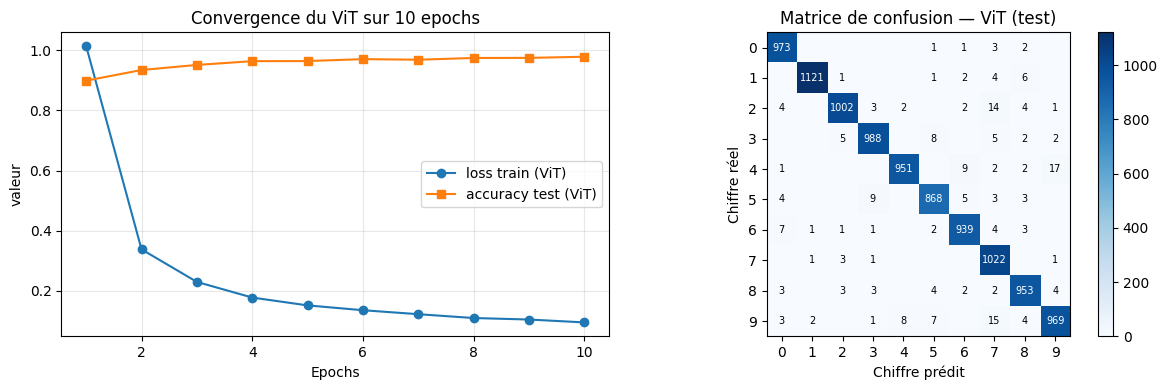

In [ ]:
# Evaluation complete du ViT sur le test : accuracy, F1, loss, matrice de confusion
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import numpy as np

vit.eval()
all_preds, all_labels = [], []
cumul_test = 0.0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        sortie = vit(images)
        cumul_test += perte_vit(sortie, labels).item() * len(labels)
        all_preds.append(sortie.argmax(1).cpu())
        all_labels.append(labels.cpu())

preds  = torch.cat(all_preds).numpy()
labels = torch.cat(all_labels).numpy()

accuracy_vit = accuracy_score(labels, preds)
f1_vit       = f1_score(labels, preds, average="macro")
loss_test_vit = cumul_test / len(test_set)

print(f"Accuracy test : {accuracy_vit:.4f}")
print(f"F1 macro test : {f1_vit:.4f}")
print(f"Loss test     : {loss_test_vit:.4f}")

# Courbes Loss et Accuracy / Epochs, comme pour le CNN (partie 1)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, 11)
ax[0].plot(epochs, historique_vit["loss_train"], marker="o", label="loss train (ViT)")
ax[0].plot(epochs, historique_vit["accuracy_test"], marker="s", color="tab:orange", label="accuracy test (ViT)")
ax[0].set_xlabel("Epochs"); ax[0].set_ylabel("valeur"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title("Convergence du ViT sur 10 epochs")

matrice = confusion_matrix(labels, preds)
im = ax[1].imshow(matrice, cmap="Blues")
ax[1].set_xticks(range(10), range(10)); ax[1].set_yticks(range(10), range(10))
for i in range(10):
    for j in range(10):
        if matrice[i, j] != 0:
            ax[1].text(j, i, matrice[i, j], ha="center", va="center",
                       color="white" if matrice[i, j] > matrice.max()/2 else "black", fontsize=7)
ax[1].set_xlabel("Chiffre prédit"); ax[1].set_ylabel("Chiffre réel")
ax[1].set_title("Matrice de confusion — ViT (test)")
fig.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.savefig("vit_convergence_et_matrice.png", dpi=120, bbox_inches="tight")
plt.show()

# Question 2 — Interprétation des résultats et comparaison avec la partie 1
#
# ---

,Accuracy test,F1 macro,Loss test,Entrainement (s)
CNN from scratch,0.9906,0.9906,0.0284,67.3
Faster R-CNN,0.9940,0.9940,0.0395,1293.3
ViT from scratch,0.9786,0.9784,0.0703,176.2


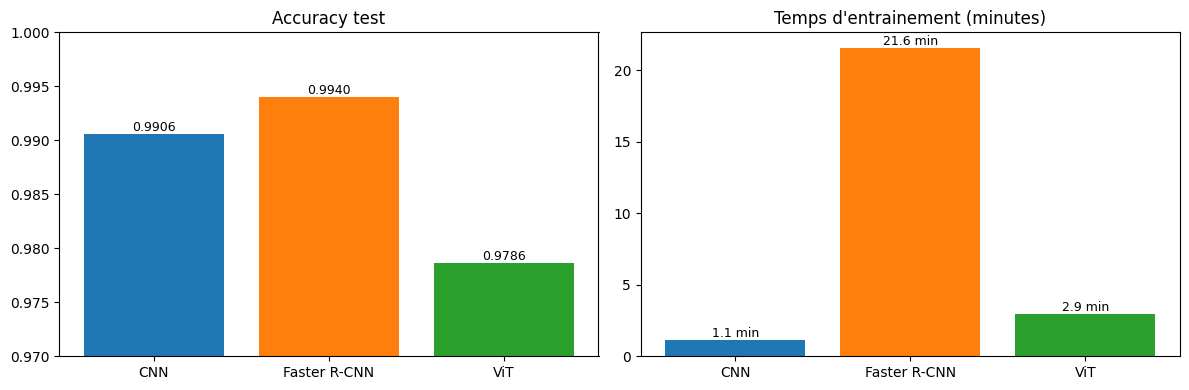

Le ViT est 2.6x plus lent a entraîner que le CNN,
et son accuracy est plus basse de 1.20 points.


In [ ]:
# Tableau de synthese ViT vs les modeles de la partie 1 (question 2)
import pandas as pd
import matplotlib.pyplot as plt

bilan_vit = pd.DataFrame({
    "Accuracy test"  : [accuracy_cnn, accuracy_frcnn, accuracy_vit],
    "F1 macro"       : [f1_cnn, f1_frcnn, f1_vit],
    "Loss test"      : [loss_test_cnn, loss_test_frcnn, loss_test_vit],
    "Entrainement (s)" : [temps_entrainement_cnn, temps_entrainement_frcnn, temps_entrainement_vit],
}, index=["CNN from scratch", "Faster R-CNN", "ViT from scratch"])
bilan_vit = bilan_vit.style.format({"Accuracy test": "{:.4f}", "F1 macro": "{:.4f}", "Loss test": "{:.4f}", "Entrainement (s)": "{:.1f}"})
display(bilan_vit)

etiquettes = ["CNN", "Faster R-CNN", "ViT"]
valeurs_acc = [accuracy_cnn, accuracy_frcnn, accuracy_vit]
valeurs_tem = [temps_entrainement_cnn / 60, temps_entrainement_frcnn / 60, temps_entrainement_vit / 60]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(etiquettes, valeurs_acc, color=["tab:blue", "tab:orange", "tab:green"])
ax[0].set_ylim(0.97, 1.0); ax[0].set_title("Accuracy test")
for i, v in enumerate(valeurs_acc): ax[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[1].bar(etiquettes, valeurs_tem, color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set_title("Temps d'entrainement (minutes)")
for i, v in enumerate(valeurs_tem): ax[1].text(i, v, f"{v:.1f} min", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("comparaison_vit_partie1.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Le ViT est {temps_entrainement_vit / temps_entrainement_cnn:.1f}x plus lent a entraîner que le CNN,")
print(f"et son accuracy est plus basse de {(accuracy_cnn - accuracy_vit) * 100:.2f} points.")

# Interprétation — pourquoi le ViT reste derrière le CNN ici ?
#
# **L'écart (0,9786 contre 0,9906) est typique et s'explique bien :**
#
# 1. **Le ViT n'a aucun degré de localité acquis.** Le CNN sait d'avance qu'un pixel voisin compte (principe
#    de convolution) et qu'un motif se déplaçant reste le même motif (invariance translationnelle). Le ViT part
#    de rien : sa seule notion de localité est dans les embeddings de position, qu'il doit apprendre.
# 2. **La petite taille du jeu de données pénalise l'attention.** Les Transformers dévoilent leur puissance sur
#    de très gros volumes de données (ViT s'est imposé d'abord sur ImageNet-21k). Sur 60 000 images simples,
#    le CNN atteint vite son plafond quand le ViT apprend encore sa grammaire visuelle.
# 3. **La courbe de convergence n'est pas saturée** (accuracy test montait encore de 0,8991 à 0,9786 en fin
#    d'entraînement) : plus d'epochs ou des patchs plus fins (par exemple 3x3) feraient probablement monter le
#    score. On conserve 10 epochs pour garder un comparatif fidèle avec les autres modèles.
#
# **En clair :** sur une petite tâche comme MNIST, une architecture convolutive bien réglée garde le meilleur
# compromis. Le ViT devient plus rentable à grande échelle : les données massives changent la donne.
#
# ---

# Synthèse — ce que j'ai appris pendant ce lab
#
# 1. **Les quatre architectures font presque jeu égal sur MNIST (98,7 - 99,4 %)** : sur une tâche simple, le
#    critère décisif n'est pas le score mais le coût — le petit CNN (0,4 M de paramètres, 1,1 min) domine le
#    compromis, tandis que le Faster R-CNN (19 M, 21,5 min) mobilise une puissance de détection inutile ici.
# 2. **Le transfert depuis ImageNet (VGG16, AlexNet) n'a rien apporté sur MNIST** : images 28x28 en niveaux
#    de gris contre 224x224 en couleur — les features pré-entraînées coûtent plus cher qu'elles ne rapportent.
# 3. **Construire un ViT de zéro tient en peu de PyTorch** : découpe en patchs, jeton CLS, embeddings de
#    position, attention multi-têtes, blocs Transformer, tête de classification ; chaque brique reste lisible.
# 4. **Sans prior de localité ni volume de données massif, le ViT perd face au CNN** (0,9786 contre 0,9906) :
#    les Transformers visuels ont besoin de beaucoup de données, leur bénéfice se matérialise à grande échelle.
# 5. **Comparer des modèles, c'est aussi comparer leur temps** : accuracy, F1 et loss ne suffisent pas pour
#    arbitrer une architecture ; le temps d'entraînement (question 3 de la partie 1) fait partie de la décision.
#
# ---